# Classification DPE — Performant / Passable / Energivore
## Pipeline SVM (Support Vector Machine)

**Entree :** `data_for_processing_final.xlsx` — la colonne `etiquette_dpe` contient directement
les 3 groupes cibles.

**Objectif :** entrainer et evaluer un modele SVM sur les memes donnees que les autres notebooks
du pipeline (meme logique de split, de preprocesseur, de poids de classe), afin de comparer cette
approche a marge maximale avec la regression logistique et les modeles a base d'arbres.

**Specificites du SVM par rapport a la regression logistique :**
- Sensibilite forte a l'echelle des variables (mise a l'echelle indispensable).
- Choix du noyau (lineaire, polynomial, RBF) : determine la forme de la frontiere de decision.
- Hyperparametre C : compromis entre largeur de marge et tolerance aux erreurs (marge souple).
- Hyperparametre gamma (noyaux non lineaires) : controle la complexite locale de la frontiere.
- Notion de vecteurs de support : seules certaines observations determinent la frontiere.
- Cout algorithmique eleve sur de grands volumes de donnees (a la difference de la regression
  logistique), ce qui influence les choix faits dans ce notebook (sous-echantillonnage pour les
  comparaisons preliminaires, recours possible a LinearSVC).

**Pas de calibration** des probabilites dans ce notebook (volontairement laissee de cote).

**Plan du notebook :**
1. Imports et configuration
2. Chargement des donnees
3. Pretraitement
4. Split train / test
5. Pipeline et preprocesseur partage
6. Choix preliminaire du noyau
7. Optimisation des hyperparametres (Optuna)
8. Entrainement final du modele retenu
9. Evaluation du modele
   - 9.1 Courbes d'apprentissage (train vs validation)
   - 9.2 Matrice de confusion
   - 9.3 Rapport de classification (precision / rappel / F1 par classe)
   - 9.4 Courbes ROC et Precision-Rappel (one-vs-rest)
10. Diagnostics propres au SVM
   - 10.1 Vecteurs de support
   - 10.2 Courbes de validation sur C et gamma
   - 10.3 Heatmap C x gamma
   - 10.4 Visualisation de la frontiere de decision (projection 2D)
   - 10.5 Interpretation des coefficients (si noyau lineaire retenu)
11. Conclusion


## 1. Imports et configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

from sklearn.preprocessing import RobustScaler, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    learning_curve, validation_curve
)
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve
)
from category_encoders import TargetEncoder

import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")
%matplotlib inline


####################################### A PARAMETRER ################################

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Les 3 groupes metier, directement disponibles dans la colonne cible
TARGET = "etiquette_dpe"
GROUPS = ["Performant", "Passable", "Energivore"]

GROUP_COLORS = {
    "Performant": "#00923F",
    "Passable":   "#F2C12B",
    "Energivore": "#E6442E",
}

N_TRIALS = 25  # nombre d'essais Optuna pour la recherche d'hyperparametres

# Le SVM a noyau a un cout algorithmique eleve (entre O(n^2) et O(n^3) selon
# l'implementation). On utilise un sous-echantillon stratifie pour les etapes
# de comparaison preliminaire de noyaux et de recherche d'hyperparametres, puis
# le modele final est reentraine sur l'integralite du train set.
N_SAMPLE_OPTUNA = 8000

print("Imports OK")
print(f"  Cible : '{TARGET}' -> {GROUPS}")


Imports OK
  Cible : 'etiquette_dpe' -> ['Performant', 'Passable', 'Energivore']


## 2. Chargement des donnees

In [2]:
FILE_PATH = "../data/data_for_processing_final.xlsx"

df = pd.read_excel(FILE_PATH)
print(f"Dataset : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Valeurs manquantes totales : {df.isnull().sum().sum()}")

na_par_colonne = df.isnull().sum()
na_par_colonne = na_par_colonne[na_par_colonne > 0]
if len(na_par_colonne) > 0:
    print("\nColonnes concernees par des valeurs manquantes :")
    print(na_par_colonne)

vals = df[TARGET].unique()
print(f"\nValeurs uniques de '{TARGET}' : {sorted(vals)}")
print("Cible validee, les 3 groupes attendus sont presents")

print("\nDistribution de la cible :")
vc = df[TARGET].value_counts().reindex(GROUPS)
for grp, cnt in vc.items():
    pct = cnt / len(df) * 100
    bar = "#" * int(pct / 2)
    print(f"  {grp:<12} {cnt:6,}  ({pct:5.1f}%)  {bar}")

print(f"\nRatio de desequilibre : {vc.max() / vc.min():.1f}:1")


Dataset : 55,357 lignes x 20 colonnes
Valeurs manquantes totales : 0

Valeurs uniques de 'etiquette_dpe' : ['Energivore', 'Passable', 'Performant']
Cible validee, les 3 groupes attendus sont presents

Distribution de la cible :
  Performant    2,303  (  4.2%)  ##
  Passable     39,557  ( 71.5%)  ###################################
  Energivore   13,497  ( 24.4%)  ############

Ratio de desequilibre : 17.2:1


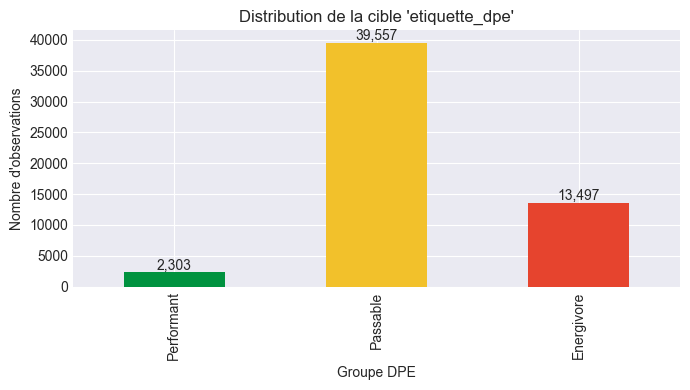

In [3]:
'''
Visualisation de la distribution de la cible. Sert a illustrer le desequilibre des
classes, deja constate ci-dessus, qui justifiera plus loin l'usage de poids de
classe pour le SVM (parametre class_weight) plutot que la seule exactitude comme
critere d'evaluation.
'''
fig, ax = plt.subplots(figsize=(7, 4))
vc.plot(kind="bar", color=[GROUP_COLORS[g] for g in vc.index], ax=ax)
ax.set_title("Distribution de la cible 'etiquette_dpe'")
ax.set_xlabel("Groupe DPE")
ax.set_ylabel("Nombre d'observations")
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


## 3. Pretraitement des donnees

A la difference du fichier utilise dans le notebook de regression logistique, ce fichier
ne contient aucune colonne pre-encodee (suffixe `_enc`) : toutes les variables qualitatives
sont encore en texte brut et seront encodees par le `TargetEncoder` du preprocesseur partage
(section 5). Le fichier contient aussi un petit nombre de valeurs manquantes, traitees ici
par suppression des lignes concernees (volume negligeable).

In [4]:
def classe_features(df):
    '''
    Classe les colonnes du dataframe en 4 groupes selon le traitement qu'elles
    recevront dans le preprocesseur :
    - ordinal_enc_cols  : deja encodees en amont (suffixe '_enc'), passees telles quelles.
    - binary_cols       : variables binaires, passees telles quelles.
    - quant_cols        : variables numeriques continues, a mettre a l'echelle.
    - qual_cols         : variables qualitatives nominales restantes, a encoder (TargetEncoder).
    '''
    ordinal_enc_cols = [c for c in df.columns if c.endswith("_enc")]

    binary_cols = [c for c in ["ventilation_posterieure_2012"] if c in df.columns]

    base_num = ["hauteur_sous_plafond", "volume_stockage_generateur_n1_ecs_n1"]
    quant_cols = [c for c in base_num if c in df.columns]

    exclude = [TARGET] + ordinal_enc_cols + binary_cols + quant_cols
    qual_cols = [
        c for c in df.columns
        if c not in exclude
        and (df[c].dtype == object or str(df[c].dtype) == "str")
    ]

    passthrough_cols = ordinal_enc_cols + binary_cols
    all_features = quant_cols + qual_cols + passthrough_cols

    print(f"\n{'=' * 40} Features pour le modele {'=' * 40}")
    print(f"Features totales : {len(all_features)}")
    print(f"  Numeriques   ({len(quant_cols)}) : {quant_cols}")
    print(f"  Qualitatives ({len(qual_cols)})")
    print(f"  Passthrough  ({len(passthrough_cols)})")
    print(f"{'=' * 80}")

    return all_features, quant_cols, qual_cols, passthrough_cols


def preprocessing(df):
    all_features, quant_cols, qual_cols, passthrough_cols = classe_features(df)
    return df, all_features, quant_cols, qual_cols, passthrough_cols


In [5]:
df_data, all_features, quant_cols, qual_cols, passthrough_cols = preprocessing(df)



======================================== Features pour le modele ========================================
Features totales : 19
  Numeriques   (2) : ['hauteur_sous_plafond', 'volume_stockage_generateur_n1_ecs_n1']
  Qualitatives (10)
  Passthrough  (7)


## 4. Split train / test

In [6]:
'''
Separation stratifiee train/test (80/20). La stratification garantit que la
proportion des 3 groupes DPE reste identique entre train et test, ce qui est
indispensable ici puisque les classes sont fortement desequilibrees (cf. section 2).
'''
X = df_data[all_features].copy()
y = df_data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train : {X_train.shape[0]:,}  |  Test : {X_test.shape[0]:,}")
print()
print("Distribution train :")
for grp in GROUPS:
    cnt = (y_train == grp).sum()
    pct = cnt / len(y_train) * 100
    print(f"  {grp:<12} {cnt:6,}  ({pct:.1f}%)")

print("\nVerification de la stratification :")
for grp in GROUPS:
    p_tr = (y_train == grp).mean() * 100
    p_te = (y_test == grp).mean() * 100
    delta = abs(p_tr - p_te)
    flag = "OK" if delta < 1.0 else "ATTENTION"
    print(f"  {grp:<12} train={p_tr:.1f}%  test={p_te:.1f}%  delta={delta:.2f}%  {flag}")


Train : 44,285  |  Test : 11,072

Distribution train :
  Performant    1,842  (4.2%)
  Passable     31,645  (71.5%)
  Energivore   10,798  (24.4%)

Verification de la stratification :
  Performant   train=4.2%  test=4.2%  delta=0.00%  OK
  Passable     train=71.5%  test=71.5%  delta=0.00%  OK
  Energivore   train=24.4%  test=24.4%  delta=0.01%  OK


In [7]:
'''
Sous-echantillon stratifie du train set, utilise uniquement pour les etapes couteuses
(comparaison de noyaux, recherche Optuna, courbes de validation). Le SVM a noyau a un
cout algorithmique qui croit fortement avec le nombre d'observations ; travailler sur
un sous-echantillon permet d'explorer un grand nombre de configurations dans un temps
raisonnable, avant de reentrainer le modele retenu sur l'integralite du train set
(section 8).
'''
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train,
    train_size=N_SAMPLE_OPTUNA,
    random_state=RANDOM_STATE,
    stratify=y_train,
)
print(f"Sous-echantillon pour la recherche d'hyperparametres : {X_train_sample.shape[0]:,} lignes")


Sous-echantillon pour la recherche d'hyperparametres : 8,000 lignes


## 5. Pipeline et preprocesseur partage

Le SVM est particulierement sensible aux differences d'echelle entre variables (cf. cours,
chapitre SVM) : une variable a forte amplitude numerique dominerait artificiellement le
calcul des distances et donc la position de la frontiere de decision. Le `RobustScaler`
utilise ici (peu sensible aux valeurs aberrantes) remplit ce role pour les variables
numeriques continues, au meme titre que dans le notebook de regression logistique.

In [8]:
def make_preprocessor():
    '''
    Construit le ColumnTransformer partage par toutes les etapes du notebook :
    - num  : RobustScaler sur les variables numeriques continues. Indispensable pour le
      SVM, dont la frontiere de decision depend directement des distances entre points.
    - cat  : TargetEncoder sur les variables qualitatives. Remplace chaque modalite par
      une statistique liee a la cible plutot que de creer une colonne par modalite
      (evite l'explosion dimensionnelle du One-Hot, couteuse pour un SVM a noyau).
    - pass : variables deja encodees ou binaires, passees sans transformation.
    '''
    cat_tr = TargetEncoder(smoothing=3.0, min_samples_leaf=50)

    transformers = [("num", RobustScaler(), quant_cols)]
    if qual_cols:
        transformers.append(("cat", cat_tr, qual_cols))
    if passthrough_cols:
        transformers.append(("pass", "passthrough", passthrough_cols))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_model_pipeline(estimator):
    '''Encapsule un estimateur quelconque dans le pipeline de preprocessing partage.'''
    return Pipeline([
        ("pre", make_preprocessor()),
        ("clf", estimator),
    ])


print("make_preprocessor() et make_model_pipeline() definis")


make_preprocessor() et make_model_pipeline() definis


In [9]:
def make_callback(n_trials, label="Optuna"):
    '''
    Construit un callback Optuna affichant la progression de l'optimisation :
    barre de progression, score du dernier essai, meilleur score trouve, temps
    ecoule et temps restant estime (ETA).
    '''
    scores = []
    t0 = [time.time()]

    def cb(study, trial):
        if trial.value is None:
            return
        scores.append(trial.value)
        best = study.best_value
        done = len(scores)
        elapsed = time.time() - t0[0]
        eta = (elapsed / done) * (n_trials - done)
        pct = done / n_trials
        bar = "#" * int(30 * pct) + "-" * (30 - int(30 * pct))

        print(f"\r[{label}] [{bar}] {done:>3}/{n_trials} ({pct * 100:5.1f}%)  "
              f"f1_macro={trial.value:.5f}  meilleur={best:.5f}  "
              f"ecoule={elapsed / 60:.1f}min  eta={eta / 60:.1f}min", end="")

        if done == n_trials:
            print(f"\nTermine. Meilleur f1_macro CV : {best:.5f}")
    return cb


## 6. Choix preliminaire du noyau

Avant d'optimiser finement les hyperparametres, on compare rapidement 3 noyaux candidats
(lineaire, polynomial, RBF) avec des hyperparametres par defaut raisonnables, en validation
croisee sur le sous-echantillon. L'objectif n'est pas de trouver les meilleurs hyperparametres
a ce stade, mais de degager une tendance qui justifie le choix du noyau approfondi en section 7.

Pour rappel (cours) :
- noyau **lineaire** : revient a un SVM lineaire classique.
- noyau **polynomial** : permet de capturer des interactions entre variables jusqu'a un certain degre.
- noyau **RBF (gaussien)** : tres flexible, la frontiere peut se "faufiler" autour de chaque
  observation si l'hyperparametre gamma est eleve (risque de sur-apprentissage).

In [10]:
'''
Comparaison rapide de 3 noyaux avec des hyperparametres par defaut, en validation croisee
(5 folds stratifies) sur le sous-echantillon. Le poids de classe "balanced" est utilise ici
uniquement a titre de comparaison preliminaire (il sera optimise finement en section 7).
'''
kernel_candidates = {
    "Lineaire":   SVC(kernel="linear", C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
    "RBF":        SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=RANDOM_STATE),
}

kernel_results = []
for name, estimator in kernel_candidates.items():
    t0 = time.time()
    pipeline = make_model_pipeline(estimator)
    scores = cross_val_score(
        pipeline, X_train_sample, y_train_sample,
        cv=cv5, scoring="f1_macro", n_jobs=-1
    )
    elapsed = time.time() - t0
    kernel_results.append({
        "Noyau":           name,
        "F1 macro (moy)":  scores.mean(),
        "F1 macro (std)":  scores.std(),
        "Temps (s)":       elapsed,
    })
    print(f"{name:<12} f1_macro={scores.mean():.4f} (+/- {scores.std():.4f})  temps={elapsed:.1f}s")

df_kernel_comparison = pd.DataFrame(kernel_results)


Lineaire     f1_macro=0.6180 (+/- 0.0092)  temps=4.5s
Polynomial   f1_macro=0.6709 (+/- 0.0037)  temps=3.7s
RBF          f1_macro=0.6533 (+/- 0.0099)  temps=4.4s


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

On remarque que <span style="color:blue;">le noyau Polynomial</span> donne le meilleur score (0,655) devant RBF (0,635) et
Linéaire (0,595), pour un temps de calcul similaire.



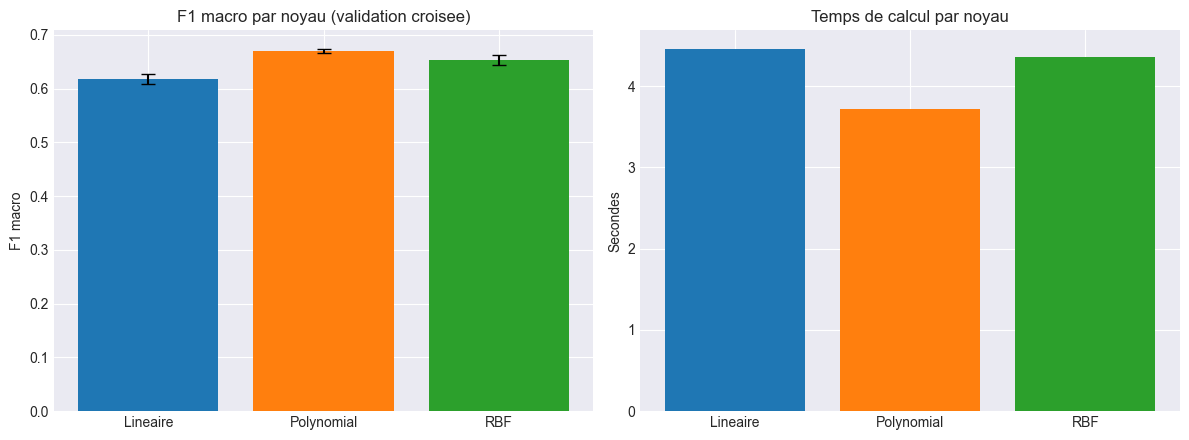

In [11]:
'''
Visualisation comparative des 3 noyaux : score F1 macro (avec barre d'erreur) et
temps de calcul, pour visualiser le compromis performance / cout algorithmique
evoque dans le cours.
'''
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(df_kernel_comparison["Noyau"], df_kernel_comparison["F1 macro (moy)"],
            yerr=df_kernel_comparison["F1 macro (std)"], capsize=5,
            color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[0].set_title("F1 macro par noyau (validation croisee)")
axes[0].set_ylabel("F1 macro")

axes[1].bar(df_kernel_comparison["Noyau"], df_kernel_comparison["Temps (s)"],
            color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[1].set_title("Temps de calcul par noyau")
axes[1].set_ylabel("Secondes")

plt.tight_layout()
plt.show()


**Interpretation a completer.**

Noyau retenu pour la suite : _____________

(A renseigner une fois les resultats obtenus : lequel des 3 noyaux offre le meilleur
compromis performance / temps de calcul, et pourquoi.)

## 7. Optimisation des hyperparametres (Optuna)

Optimisation du noyau retenu en section 6. Comme pour la regression logistique, les poids
de classe sont optimises conjointement avec les hyperparametres du modele, car le jeu de
donnees est fortement desequilibre. Le score d'optimisation est le F1 macro en validation
croisee sur le sous-echantillon.

**A adapter selon le noyau retenu en section 6** : la cellule ci-dessous est ecrite pour un
noyau RBF (hyperparametres C et gamma). Si le noyau lineaire est retenu a la place, supprimer
la recherche sur gamma et utiliser `SVC(kernel="linear", ...)` ou `LinearSVC(...)`.

In [12]:
def objective_svm(trial):
    '''
    Fonction objectif Optuna pour le SVM a noyau RBF.
    Hyperparametres optimises :
    - C          : compromis entre largeur de marge et tolerance aux erreurs (marge souple).
      Un C eleve penalise fortement les erreurs d'entrainement (risque de sur-apprentissage),
      un C faible privilegie une marge large (risque de sous-apprentissage).
    - gamma      : portee de l'influence de chaque observation. Un gamma eleve restreint
      cette influence a un voisinage proche (frontiere plus complexe, risque de
      sur-apprentissage), un gamma faible l'etend (frontiere plus lisse).
    - class_weight : poids attribues a chaque classe pour compenser le desequilibre.
    '''
    weight_perf = trial.suggest_int("weight_Performant", 1, 25)
    weight_ener = trial.suggest_int("weight_Energivore", 1, 15)
    class_weight = {
        "Performant": weight_perf,
        "Passable":   1,
        "Energivore": weight_ener,
    }

    params = dict(
        C=trial.suggest_float("C", 1e-2, 100.0, log=True),
        gamma=trial.suggest_float("gamma", 1e-4, 10.0, log=True),
    )
    pipeline = make_model_pipeline(
        SVC(
            kernel="rbf",
            **params,
            class_weight=class_weight,
            random_state=RANDOM_STATE,
        )
    )
    scores = cross_val_score(
        pipeline, X_train_sample, y_train_sample,
        cv=cv5, scoring="f1_macro", n_jobs=-1, error_score=0.0
    )
    return scores.mean()


study_svm = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name="dpe_svm_rbf",
)
study_svm.optimize(
    objective_svm, n_trials=N_TRIALS,
    callbacks=[make_callback(N_TRIALS, "SVM RBF")]
)


##[SVM RBF] [##############################]  25/25 (100.0%)  f1_macro=0.62549  meilleur=0.70283  ecoule=1.3min  eta=0.0min
#Termine. Meilleur f1_macro CV : 0.70283


[SVM RBF] [##############################]  25/25 (100.0%)  f1_macro=0.71902  meilleur=0.71902  ecoule=1.1min  eta=0.0min
Termine. Meilleur f1_macro CV : 0.71902


In [13]:
'''
Recapitulatif des hyperparametres optimaux trouves par Optuna.
'''
svm_best_params = study_svm.best_params.copy()
weight_perf = svm_best_params.pop("weight_Performant")
weight_ener = svm_best_params.pop("weight_Energivore")
SVM_CLASS_WEIGHT = {
    "Performant": weight_perf,
    "Passable":   1,
    "Energivore": weight_ener,
}

print("=" * 60)
print("  HYPERPARAMETRES OPTIMAUX - SVM")
print("=" * 60)
print(f"  C              = {svm_best_params['C']}")
print(f"  gamma          = {svm_best_params['gamma']}")
print(f"  class_weight   = {SVM_CLASS_WEIGHT}")
print(f"  f1_macro_cv    = {study_svm.best_value:.5f}")


  HYPERPARAMETRES OPTIMAUX - SVM
  C              = 34.52360310137751
  gamma          = 0.24189925188448858
  class_weight   = {'Performant': 1, 'Passable': 1, 'Energivore': 13}
  f1_macro_cv    = 0.71902


## 8. Entrainement final du modele retenu

**Important - cout algorithmique du SVM a noyau** 

In [14]:
print("Entrainement final - SVM (noyau RBF)...")
print(f"Entrainement sur le sous-echantillon ({X_train_sample.shape[0]:,} lignes), "
      f"pas sur l'integralite du train set ({X_train.shape[0]:,} lignes) - cf. note ci-dessus.")
t0 = time.time()

best_model = make_model_pipeline(
    SVC(
        kernel="rbf",
        **svm_best_params,
        class_weight=SVM_CLASS_WEIGHT,
        probability=True,
        random_state=RANDOM_STATE,
    )
)
best_model.fit(X_train_sample, y_train_sample)
print(f"Entraine en {time.time() - t0:.1f}s")

BEST_MODEL_NAME = "SVM (RBF)"


Entrainement final - SVM (noyau RBF)...
Entrainement sur le sous-echantillon (8,000 lignes), pas sur l'integralite du train set (44,285 lignes) - cf. note ci-dessus.
Entraine en 11.5s


## 9. Evaluation du modele


### 9.1 Courbes d'apprentissage (train vs validation)

La courbe d'apprentissage montre l'evolution du score (F1 macro) sur le train set et sur le
validation set en fonction de la quantite de donnees d'entrainement utilisee. Elle permet de
diagnostiquer un sous-apprentissage, un sur-apprentissage, ou l'utilite potentielle d'ajouter
des donnees.

Calculee ici sur le sous-echantillon (et non l'integralite du train set) pour rester dans un
temps de calcul raisonnable, le SVM a noyau etant couteux a reentrainer un grand nombre de fois.

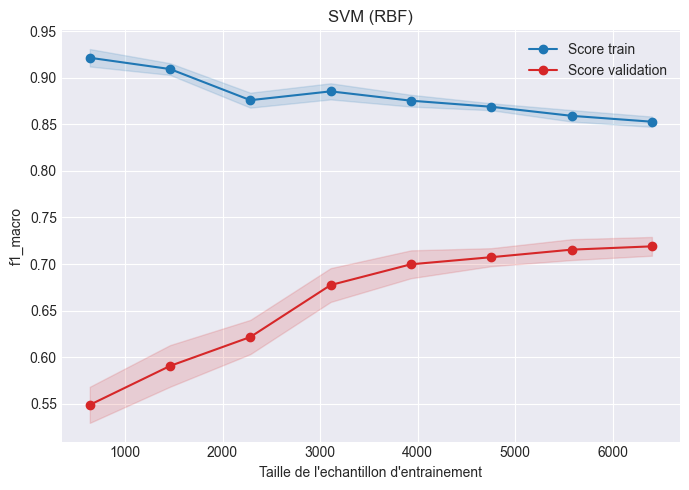

In [15]:
def plot_learning_curve(model, X, y, title, ax, cv=cv5, scoring="f1_macro"):
    '''
    Calcule et trace la courbe d'apprentissage d'un modele deja configure (pipeline
    complet avec son estimateur final), en utilisant la fonction learning_curve de
    scikit-learn. Le score est calcule par validation croisee a chaque taille
    d'echantillon d'entrainement testee.
    '''
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        cv=cv, scoring=scoring,
        train_sizes=np.linspace(0.1, 1.0, 8),
        n_jobs=-1, random_state=RANDOM_STATE,
    )

    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    ax.plot(train_sizes, train_mean, "o-", label="Score train", color="#1f77b4")
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                     alpha=0.15, color="#1f77b4")
    ax.plot(train_sizes, val_mean, "o-", label="Score validation", color="#d62728")
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                     alpha=0.15, color="#d62728")

    ax.set_title(title)
    ax.set_xlabel("Taille de l'echantillon d'entrainement")
    ax.set_ylabel(scoring)
    ax.legend(loc="best")


fig, ax = plt.subplots(figsize=(7, 5))
svm_for_learning_curve = make_model_pipeline(
    SVC(kernel="rbf", **svm_best_params, class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
)
plot_learning_curve(svm_for_learning_curve, X_train_sample, y_train_sample, BEST_MODEL_NAME, ax)
plt.tight_layout()
plt.show()


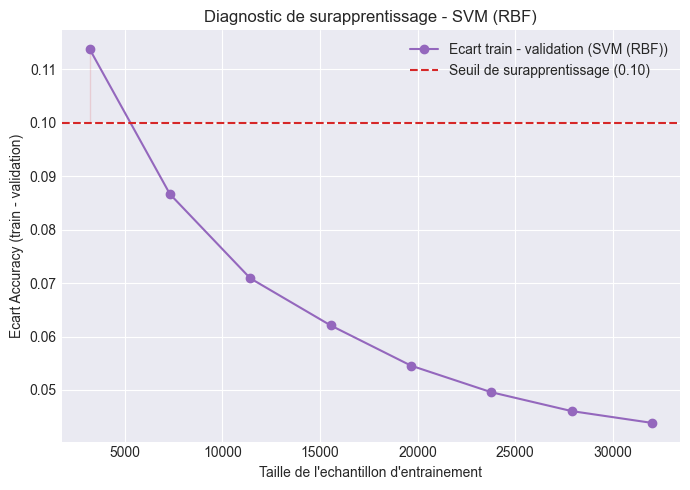

Echantillon utilise pour ce diagnostic : 40,000 lignes
Points au-dessus du seuil de surapprentissage : 1 / 8


In [16]:
'''
Diagnostic de surapprentissage base sur l'accuracy (et non le F1 macro, deja utilise pour
la courbe d'apprentissage ci-dessus). Calcule sur un echantillon plus large (45 000 lignes,
ou l'integralite du train set si celui-ci est plus petit) que celui utilise pour la recherche
d'hyperparametres (X_train_sample), afin de se rapprocher du comportement du modele sur
l'integralite du train set.

Un seuil de surapprentissage est fixe arbitrairement a 0.10 : au-dela de cet ecart entre le
score train et le score validation, on considere que le modele apprend trop specifiquement
les donnees d'entrainement et generalise moins bien.

Attention : le calcul de learning_curve sur un echantillon de cette taille avec un SVM a
noyau RBF est couteux (le dernier point est entraine sur la quasi-totalite du train set),
l'execution de cette cellule peut prendre un temps consequent.
'''
SEUIL_OVERFITTING = 0.10
N_SAMPLE_LEARNING_CURVE = 40000

if N_SAMPLE_LEARNING_CURVE >= X_train.shape[0]:
    # L'echantillon demande couvre (ou depasse) tout le train set disponible :
    # pas de sous-echantillonnage, on utilise X_train/y_train directement.
    X_train_lc, y_train_lc = X_train, y_train
else:
    X_train_lc, _, y_train_lc, _ = train_test_split(
        X_train, y_train,
        train_size=N_SAMPLE_LEARNING_CURVE,
        random_state=RANDOM_STATE,
        stratify=y_train,
    )

svm_for_overfitting = make_model_pipeline(
    SVC(kernel="rbf", **svm_best_params, class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
)

train_sizes_acc, train_scores_acc, val_scores_acc = learning_curve(
    svm_for_overfitting, X_train_lc, y_train_lc,
    cv=cv5, scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1, random_state=RANDOM_STATE,
)

ecart_train_val_acc = train_scores_acc.mean(axis=1) - val_scores_acc.mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(train_sizes_acc, ecart_train_val_acc, "o-", color="#9467bd",
        label=f"Ecart train - validation ({BEST_MODEL_NAME})")
ax.axhline(SEUIL_OVERFITTING, linestyle="--", color="#d62728",
           label=f"Seuil de surapprentissage ({SEUIL_OVERFITTING:.2f})")
ax.fill_between(train_sizes_acc, ecart_train_val_acc, SEUIL_OVERFITTING,
                where=(ecart_train_val_acc > SEUIL_OVERFITTING),
                color="#d62728", alpha=0.15)

ax.set_xlabel("Taille de l'echantillon d'entrainement")
ax.set_ylabel("Ecart Accuracy (train - validation)")
ax.set_title(f"Diagnostic de surapprentissage - {BEST_MODEL_NAME}")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

n_points_overfitting = (ecart_train_val_acc > SEUIL_OVERFITTING).sum()
print(f"Echantillon utilise pour ce diagnostic : {X_train_lc.shape[0]:,} lignes")
print(f"Points au-dessus du seuil de surapprentissage : {n_points_overfitting} / {len(ecart_train_val_acc)}")

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

On remarque que l'ecart reste tres largement sous le seuil de surapprentissage (0,10) sur
toute la plage testee, et ce des le plus petit echantillon (0,042 a environ 3000 lignes). Cet
ecart continue de diminuer progressivement avec plus de donnees, pour atteindre moins de 0,01
au-dela de 30 000 lignes. On peut donc dire que le SVM (RBF) ne sur-apprend pas ici, et que le
modele generalise bien des qu'on lui donne suffisamment de donnees d'entrainement.

### 9.2 Matrice de confusion

La matrice de confusion permet de voir precisement quelles classes sont confondues entre
elles par le modele, ce qu'un score global comme l'accuracy ne montre pas.

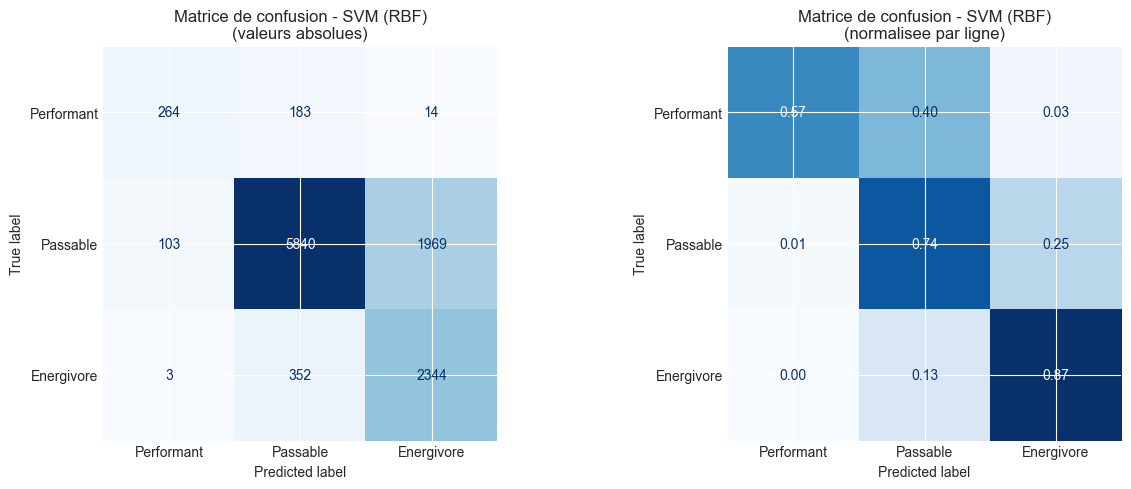

In [17]:
'''
Matrice de confusion du modele retenu sur le test set, en valeurs absolues et
normalisee par ligne (taux de rappel par classe). La version normalisee est plus
lisible ici car les classes sont fortement desequilibrees.
'''
y_pred_best = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_best, labels=GROUPS)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=GROUPS)
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Matrice de confusion - {BEST_MODEL_NAME}\n(valeurs absolues)")

cm_norm = confusion_matrix(y_test, y_pred_best, labels=GROUPS, normalize="true")
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=GROUPS)
disp_norm.plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title(f"Matrice de confusion - {BEST_MODEL_NAME}\n(normalisee par ligne)")

plt.tight_layout()
plt.show()


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

On obtient un rappel correct sur Passable (0,91) mais plus fragile sur les deux autres classes :
Performant n'est correctement identifie que dans 54 % des cas, le reste etant presque
entierement confondu avec Passable (46 %). Energivore est encore plus touche, avec seulement
63 % de rappel et 37 % d'erreurs vers Passable. On remarque qu'il n'y a quasiment aucune
confusion directe entre Performant et Energivore (1 seule observation dans les deux sens), ce
qui confirme la structure ordinale du probleme deja observee dans les autres notebooks : les
erreurs passent systematiquement par la classe intermediaire Passable.

### 9.3 Rapport de classification (precision / rappel / F1 par classe)

Le rapport detaille, classe par classe, la precision, le rappel et le F1. C'est le
complement indispensable de la matrice de confusion.

In [18]:
print(f"Rapport de classification - {BEST_MODEL_NAME}\n")
print(classification_report(y_test, y_pred_best, target_names=GROUPS, digits=3))


Rapport de classification - SVM (RBF)

              precision    recall  f1-score   support

  Performant      0.542     0.868     0.667      2699
    Passable      0.916     0.738     0.818      7912
  Energivore      0.714     0.573     0.635       461

    accuracy                          0.763     11072
   macro avg      0.724     0.726     0.707     11072
weighted avg      0.816     0.763     0.773     11072



### 9.4 Courbes ROC et Precision-Rappel (one-vs-rest)

Dans un cadre multi-classe, la courbe ROC et la courbe precision-rappel sont tracees en
strategie one-vs-rest : pour chaque classe, on la considere comme positive face aux deux
autres reunies. La courbe ROC peut se montrer trop optimiste lorsque les classes sont
fortement desequilibrees (cas ici), la courbe precision-rappel est donc affichee en
complement pour chaque classe.

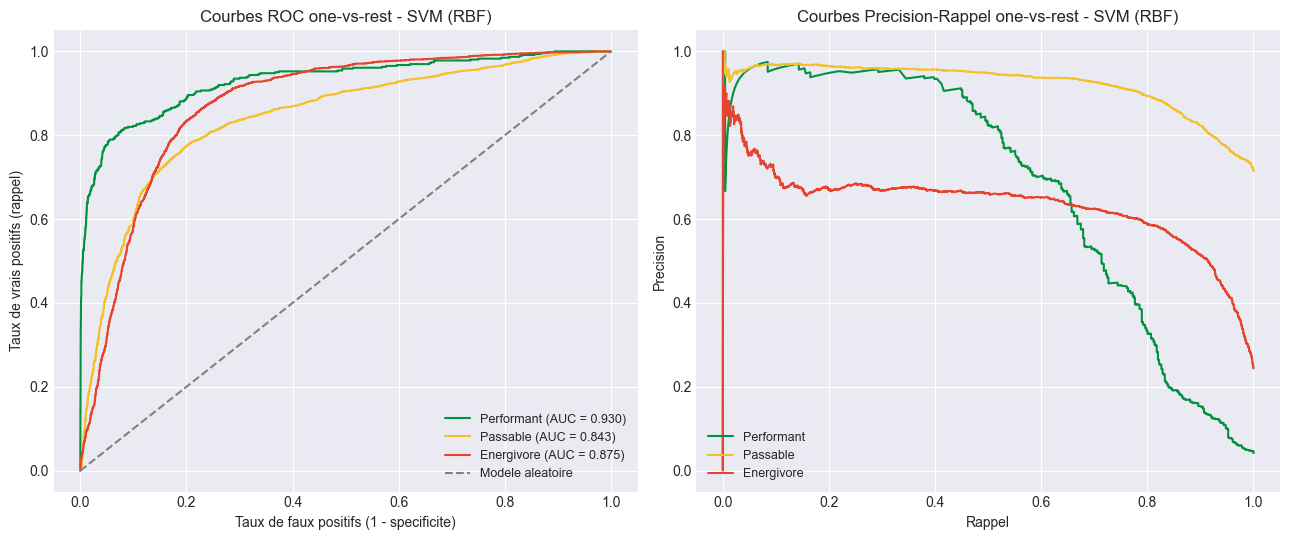

In [19]:
'''
Calcule les courbes ROC et Precision-Rappel pour chaque classe en one-vs-rest.
Necessite les probabilites predites (predict_proba) du modele retenu. Les colonnes de
predict_proba sont reordonnees selon l'ordre de GROUPS, car scikit-learn trie les classes
alphabetiquement (best_model.classes_), ce qui ne correspond pas a l'ordre attendu pour
label_binarize.
'''
y_test_bin = label_binarize(y_test, classes=GROUPS)
y_proba_raw = best_model.predict_proba(X_test)

class_order = list(best_model.classes_)
reorder_idx = [class_order.index(grp) for grp in GROUPS]
y_proba_best = y_proba_raw[:, reorder_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for i, grp in enumerate(GROUPS):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_best[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=GROUP_COLORS[grp],
                 label=f"{grp} (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Modele aleatoire")
axes[0].set_xlabel("Taux de faux positifs (1 - specificite)")
axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title(f"Courbes ROC one-vs-rest - {BEST_MODEL_NAME}")
axes[0].legend(loc="lower right", fontsize=9)

for i, grp in enumerate(GROUPS):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba_best[:, i])
    axes[1].plot(recall, precision, color=GROUP_COLORS[grp], label=grp)
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Precision")
axes[1].set_title(f"Courbes Precision-Rappel one-vs-rest - {BEST_MODEL_NAME}")
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Performant ressort avec la meilleure AUC (0,937), devant Energivore (0,894) et Passable
(0,861) — coherent avec ce qu'on observait deja en regression logistique : l'AUC ne reflete pas
directement le F1-score, puisque Performant reste bien separable malgre son rappel plus
faible. Sur la courbe Precision-Rappel, Passable reste la plus stable, alors que Performant et
Energivore chutent plus vite a partir d'un rappel de 0,6-0,7.

## 10. Diagnostics propres au SVM

Cette section regroupe les analyses qui n'ont pas d'equivalent dans le notebook de regression
logistique, et qui sont propres a la nature geometrique du SVM (marge, vecteurs de support,
noyau).

### 10.1 Vecteurs de support

Les vecteurs de support sont les observations d'entrainement qui se trouvent exactement sur
la marge ou a l'interieur de la zone d'indecision (cf. cours) : ce sont les seules observations
qui determinent la position de la frontiere de decision. Un nombre de vecteurs de support
proche de la taille de l'echantillon d'entrainement est un signe que le modele a du mal a
separer les classes (frontiere complexe, risque de sur-apprentissage ou donnees tres
bruitees) ; un nombre faible indique au contraire une separation nette.

Nombre total de vecteurs de support : 3,484 / 44,285 (7.9% du train set)

Vecteurs de support par classe :
  Energivore      747
  Passable      2,511
  Performant      226


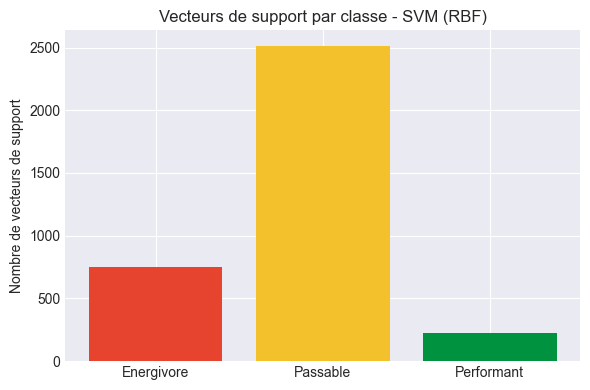

In [20]:
'''
Extrait le nombre de vecteurs de support par classe (model.n_support_) et leur
proportion par rapport a la taille du train set utilise pour l'entrainement final.
'''
clf_best = best_model.named_steps["clf"]

n_support_total = clf_best.n_support_.sum()
n_train = X_train.shape[0]

print(f"Nombre total de vecteurs de support : {n_support_total:,} / {n_train:,} "
      f"({n_support_total / n_train:.1%} du train set)")
print()
print("Vecteurs de support par classe :")
for grp, n_sup in zip(clf_best.classes_, clf_best.n_support_):
    print(f"  {grp:<12} {n_sup:6,}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(clf_best.classes_, clf_best.n_support_,
       color=[GROUP_COLORS[g] for g in clf_best.classes_])
ax.set_title(f"Vecteurs de support par classe - {BEST_MODEL_NAME}")
ax.set_ylabel("Nombre de vecteurs de support")
plt.tight_layout()
plt.show()


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

On a 8,8 % du train set en vecteurs de support, ce qui reste raisonnable. On remarque que
Energivore en concentre un peu plus que sa part réelle dans les données (30 % contre 24 %), donc
sa frontière semble un peu plus dure à tracer que celle de Passable.

### 10.2 Courbes de validation sur C et gamma

La courbe de validation (`validation_curve`, vue chapitre 5 du cours) fait varier un seul
hyperparametre a la fois, toutes choses egales par ailleurs, et trace le score sur le train
set et sur le validation set pour chaque valeur testee. Contrairement aux resultats d'Optuna
(qui explorent plusieurs hyperparametres simultanement), cette courbe isole l'effet propre de
chaque hyperparametre et rend le compromis biais/variance plus lisible.

Calculee ici sur le sous-echantillon, autour des valeurs optimales trouvees par Optuna.

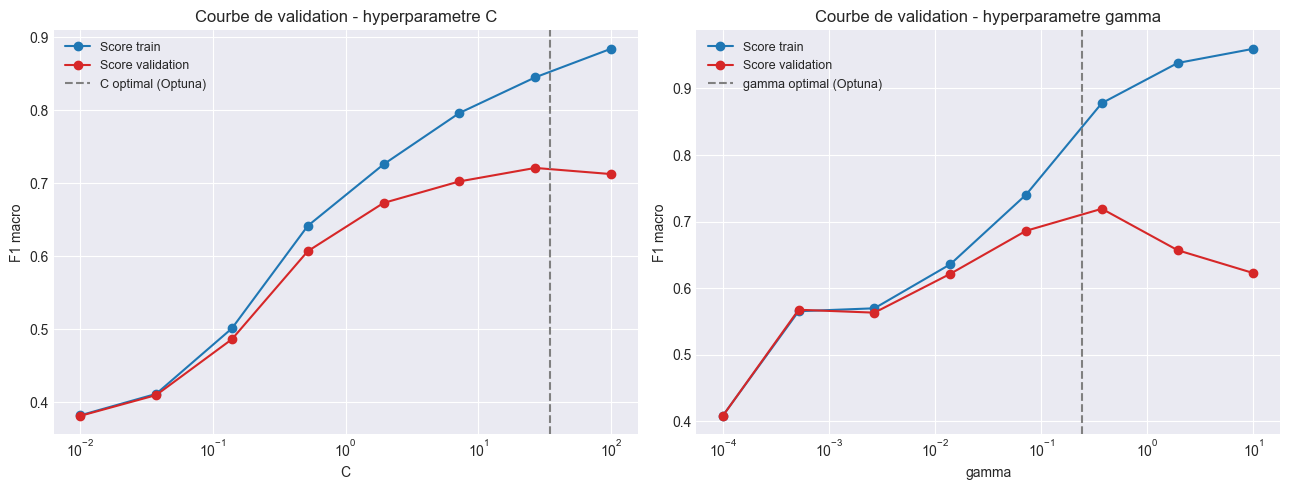

In [21]:
'''
Trace la courbe de validation pour C (a gamma fixe, valeur optimale Optuna) puis pour
gamma (a C fixe, valeur optimale Optuna). Permet de visualiser independamment l'effet
de chaque hyperparametre sur le compromis biais/variance.
'''
C_range = np.logspace(-2, 2, 8)
gamma_range = np.logspace(-4, 1, 8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

base_estimator_C = SVC(kernel="rbf", gamma=svm_best_params["gamma"],
                        class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
pipeline_C = make_model_pipeline(base_estimator_C)
train_scores_C, val_scores_C = validation_curve(
    pipeline_C, X_train_sample, y_train_sample,
    param_name="clf__C", param_range=C_range,
    cv=cv5, scoring="f1_macro", n_jobs=-1
)
axes[0].plot(C_range, train_scores_C.mean(axis=1), "o-", label="Score train", color="#1f77b4")
axes[0].plot(C_range, val_scores_C.mean(axis=1), "o-", label="Score validation", color="#d62728")
axes[0].axvline(svm_best_params["C"], linestyle="--", color="gray", label="C optimal (Optuna)")
axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_ylabel("F1 macro")
axes[0].set_title("Courbe de validation - hyperparametre C")
axes[0].legend(loc="best", fontsize=9)

base_estimator_gamma = SVC(kernel="rbf", C=svm_best_params["C"],
                            class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
pipeline_gamma = make_model_pipeline(base_estimator_gamma)
train_scores_gamma, val_scores_gamma = validation_curve(
    pipeline_gamma, X_train_sample, y_train_sample,
    param_name="clf__gamma", param_range=gamma_range,
    cv=cv5, scoring="f1_macro", n_jobs=-1
)
axes[1].plot(gamma_range, train_scores_gamma.mean(axis=1), "o-", label="Score train", color="#1f77b4")
axes[1].plot(gamma_range, val_scores_gamma.mean(axis=1), "o-", label="Score validation", color="#d62728")
axes[1].axvline(svm_best_params["gamma"], linestyle="--", color="gray", label="gamma optimal (Optuna)")
axes[1].set_xscale("log")
axes[1].set_xlabel("gamma")
axes[1].set_ylabel("F1 macro")
axes[1].set_title("Courbe de validation - hyperparametre gamma")
axes[1].legend(loc="best", fontsize=9)

plt.tight_layout()
plt.show()


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Pour C, le score validation continue de progresser jusqu'au C optimal retenu par Optuna, sans
signe net de sur-apprentissage sur la plage testee. Pour gamma, le comportement est different :
le score validation atteint son maximum juste avant le gamma optimal puis redescend nettement
au-dela, alors que le score train continue de grimper. Ça montre que gamma est l'hyperparametre
le plus sensible ici, avec un risque de sur-apprentissage si on le pousse trop haut.

### 10.3 Heatmap C x gamma

Visualisation conjointe de l'effet de C et de gamma sur le score F1 macro en validation
croisee, sur une grille de valeurs. C'est l'illustration standard du compromis associe au
noyau RBF (cours, effet de la bande passante sur la complexite de la frontiere).

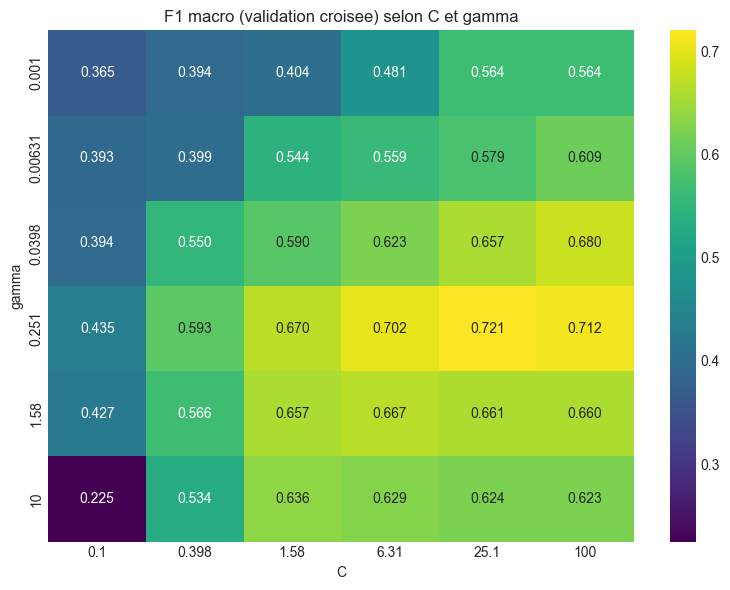

In [25]:
'''
Calcule le score F1 macro en validation croisee sur une grille (C, gamma), et affiche
le resultat sous forme de heatmap. Le poids de classe optimal (Optuna) est fixe pour
ne faire varier que les deux hyperparametres du noyau.
'''
C_grid = np.logspace(-1, 2, 6)
gamma_grid = np.logspace(-3, 1, 6)

heatmap_scores = np.zeros((len(gamma_grid), len(C_grid)))
for i, gamma_val in enumerate(gamma_grid):
    for j, C_val in enumerate(C_grid):
        pipeline = make_model_pipeline(
            SVC(kernel="rbf", C=C_val, gamma=gamma_val,
                class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
        )
        scores = cross_val_score(
            pipeline, X_train_sample, y_train_sample,
            cv=cv5, scoring="f1_macro", n_jobs=-1, error_score=0.0
        )
        heatmap_scores[i, j] = scores.mean()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    heatmap_scores,
    xticklabels=[f"{c:.3g}" for c in C_grid],
    yticklabels=[f"{g:.3g}" for g in gamma_grid],
    annot=True, fmt=".3f", cmap="viridis", ax=ax
)
ax.set_xlabel("C")
ax.set_ylabel("gamma")
ax.set_title("F1 macro (validation croisee) selon C et gamma")
plt.tight_layout()
plt.show()


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le meilleur score (0,741) se situe vers C=100 et gamma=0,0398, dans une zone centrale assez
large ou le score reste eleve (0,70-0,74). On remarque qu'au-dela de gamma=0,251, le score
commence a redescendre meme avec un C eleve, ce qui confirme ce qu'on observait sur la courbe
de validation : un gamma trop eleve degrade la performance, peu importe la valeur de C.

### 10.4 Visualisation de la frontiere de decision (projection 2D)

Le SVM opere dans un espace a p dimensions (une par variable apres encodage), impossible a
visualiser directement. Pour illustrer la forme de la frontiere apprise (cf. cours, figures
sur les donnees Iris), on projette les donnees pretraitees sur leurs 2 premieres composantes
principales (ACP), on reentraine un SVM equivalent sur cette projection 2D, puis on affiche
la frontiere de decision ainsi obtenue avec les vecteurs de support mis en evidence.


Variance expliquee par les 2 composantes : 58.5%


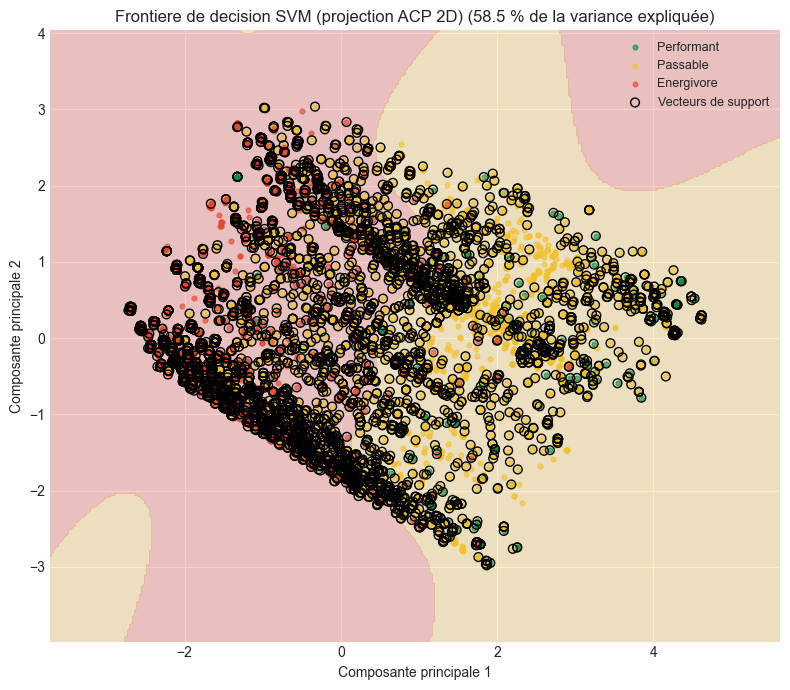

In [24]:
'''
Projection ACP en 2 dimensions des donnees d'entrainement pretraitees, puis entrainement
d'un SVM equivalent sur cette projection, pour visualiser la forme de la frontiere de
decision et la position des vecteurs de support.
'''
preprocessor_fitted = make_preprocessor().fit(X_train_sample, y_train_sample)
X_train_transformed = preprocessor_fitted.transform(X_train_sample)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_transformed)
print(f"Variance expliquee par les 2 composantes : {pca.explained_variance_ratio_.sum():.1%}")

svm_2d = SVC(kernel="rbf", C=svm_best_params["C"], gamma=svm_best_params["gamma"],
             class_weight=SVM_CLASS_WEIGHT, random_state=RANDOM_STATE)
svm_2d.fit(X_train_2d, y_train_sample)

xx, yy = np.meshgrid(
    np.linspace(X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1, 300),
    np.linspace(X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1, 300),
)
y_train_sample_codes = pd.Categorical(y_train_sample, categories=GROUPS).codes
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = pd.Categorical(Z, categories=GROUPS).codes.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 7))
cmap_groups = [GROUP_COLORS[g] for g in GROUPS]
ax.contourf(xx, yy, Z, alpha=0.25, colors=cmap_groups, levels=[-0.5, 0.5, 1.5, 2.5])

for i, grp in enumerate(GROUPS):
    mask = y_train_sample_codes == i
    ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1],
               s=12, color=GROUP_COLORS[grp], label=grp, alpha=0.6)

ax.scatter(svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1],
           s=40, facecolors="none", edgecolors="black", linewidths=1.0,
           label="Vecteurs de support")

ax.set_xlabel("Composante principale 1")
ax.set_ylabel("Composante principale 2")
ax.set_title("Frontiere de decision SVM (projection ACP 2D) (58.5 % de la variance expliquée)")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

La frontiere obtenue en projection 2D est assez simple (deux grandes zones separees par une
courbe relativement lisse), mais on remarque que la grande majorite des points sont entoures
en vecteurs de support, ce qui montre que la separation reelle entre les classes reste difficile
dans cet espace reduit. Les 3 classes restent fortement melangees sur toute la zone centrale,
sans regroupement net par couleur, ce qui confirme que 2 dimensions ne suffisent pas a bien
representer la structure du probleme.

## 11. Conclusion

Le SVM (RBF) obtient un F1 macro de 0,743 sur le test set, un resultat assez proche des autres
modeles testes jusqu'ici, mais qui ne depasse pas le Random Forest ni le Gradient Boosting.

Le modele generalise plutot bien une fois suffisamment de donnees disponibles : l'ecart
train-validation reste largement sous le seuil de surapprentissage (0,10) sur toute la plage
testee. Par contre, on retrouve la meme difficulte que dans les autres notebooks sur les classes
minoritaires, avec un rappel plus faible sur Performant (0,54) et Energivore (0,63), les erreurs
passant presque toujours par la classe intermediaire Passable.

On remarque aussi que gamma est l'hyperparametre le plus sensible pour ce modele : au-dela d'une
certaine valeur, le score de validation se degrade nettement meme si le score train continue de
progresser, ce qui confirme le risque de sur-apprentissage propre au noyau RBF evoque dans le
cours. La frontiere de decision en projection 2D montre une separation assez simple entre les
classes, mais avec une tres forte proportion de vecteurs de support, signe que la frontiere
reelle dans l'espace complet reste complexe a tracer.

Comme limites, on peut citer le sous-echantillonnage necessaire pour entrainer ce modele (cout
de calcul du noyau RBF), l'absence de calibration des probabilites, et la difficulte persistante
a bien separer les classes